# Student performance: study time and math grades

A small assisted learning project. Starter code and analysis prepared with AI assistance. Run, read and change it before presenting it as a skill.

Questions: how do final math grades differ by weekly study-time group and past class failure?

Data: UCI Student Performance, Paulo Cortez (2008), https://doi.org/10.24432/C5TG7T. Source and CC BY 4.0 license: https://archive.ics.uci.edu/dataset/320/student+performance. Only the 395-row math file is used. Historical data from two Portuguese secondary schools, not Egyptian university data.

## 1. Load the data

`pandas` reads a table. `Path` finds a local file. If it is missing, download the free public ZIP from UCI. The CSV uses semicolons rather than commas. No Drive mount or password is needed.

In [1]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import matplotlib.pyplot as plt
import pandas as pd
DATA_URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
STUDY_LABELS = {1: "<2 hours", 2: "2-5 hours", 3: "5-10 hours", 4: ">10 hours"}

def load_data(folder):
    """Use the included CSV, or download only the math file from UCI."""
    path = folder / "student-mat.csv"
    if not path.exists():
        with urlopen(DATA_URL, timeout=30) as response:
            archive = ZipFile(BytesIO(response.read()))
        # UCI's download currently contains another ZIP with the CSV inside.
        if "student.zip" in archive.namelist():
            archive = ZipFile(BytesIO(archive.read("student.zip")))
        path.write_bytes(archive.read("student-mat.csv"))
    return pd.read_csv(path, sep=";")

folder = Path.cwd()
df = load_data(folder)
df[["studytime", "failures", "G3"]].head()

,studytime,failures,G3
0,2,0,6
1,2,0,6
2,2,3,10
3,3,0,15
4,2,0,10


## 2. Check before calculating

Check the columns, missing values and ranges. We report identical rows but do not automatically remove them, because two different students could have identical answers. Final grades of zero are retained.

In [2]:
def check_data(df):
    """Stop rather than silently calculate with missing or invalid key data."""
    required = {"studytime", "failures", "G3"}
    if df.empty or not required.issubset(df.columns):
        raise ValueError("Expected nonempty UCI math data with studytime, failures and G3.")
    if df[list(required)].isna().any().any():
        raise ValueError("Missing values in the analysis columns. Inspect the CSV first.")
    if not df["studytime"].isin([1, 2, 3, 4]).all():
        raise ValueError("Unexpected study-time category.")
    if not df["G3"].between(0, 20).all() or not df["failures"].between(0, 4).all():
        raise ValueError("Grade or past-failure values outside the source's range.")
    # Report duplicates, but do not delete them: identical rows can be different students.
    print(f"Rows: {len(df)} | Columns: {len(df.columns)}")
    print(f"Missing cells: {df.isna().sum().sum()} | Full duplicate rows: {df.duplicated().sum()}")

check_data(df)

Rows: 395 | Columns: 33
Missing cells: 0 | Full duplicate rows: 0


## 3. Compare groups

`groupby` splits rows into categories. `size` counts records and `mean` averages grades. `studytime` is coded 1 to 4, so we replace those codes with the documented hour bands. `failures > 0` groups any recorded past failure together. These are descriptive averages, not predictions.

In [3]:
def summarize(df):
    """Group by study time and by whether any past class failure was recorded."""
    study = df.groupby("studytime")["G3"].agg(students="size", average_grade="mean")
    study = study.reindex([1, 2, 3, 4])
    study.index = study.index.map(STUDY_LABELS)
    study.index.name = "weekly_study_time"

    work = df.assign(past_failure=df["failures"].gt(0))
    failures = work.groupby("past_failure")["G3"].agg(students="size", average_grade="mean")
    failures.index = failures.index.map({False: "No past failure", True: "Any past failure"})
    return study, failures

study, failures = summarize(df)
print("Study-time groups:\n", study.round(2).to_string())
print("\nPast-failure groups:\n", failures.round(2).to_string())

Study-time groups:
                    students  average_grade
weekly_study_time                         
<2 hours                105          10.05
2-5 hours               198          10.17
5-10 hours               65          11.40
>10 hours                27          11.26

Past-failure groups:
                   students  average_grade
past_failure                             
No past failure        312          11.25
Any past failure        83           7.27


## 4. Make a chart

The vertical axis starts at zero and ends at 20, the full grade scale. Each bar shows its group size (`n`). The smallest group has only 27 records, so do not treat all four averages as equally precise.

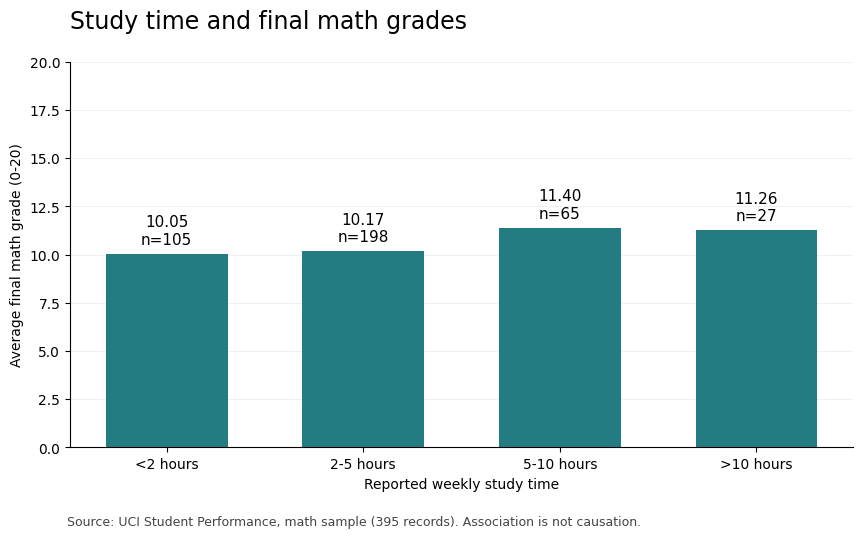

In [4]:
def plot_study_time(study, path):
    """Keep a zero baseline and show group sizes so the comparison is not misleading."""
    fig, ax = plt.subplots(figsize=(9, 5.5))
    bars = ax.bar(study.index, study["average_grade"], color="#247C83", width=0.62)
    ax.set_ylim(0, 20)
    ax.set_ylabel("Average final math grade (0-20)")
    ax.set_xlabel("Reported weekly study time")
    ax.set_title("Study time and final math grades", loc="left", fontsize=17, pad=24)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.18)
    for bar, (_, row) in zip(bars, study.iterrows()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.35,
                f"{row['average_grade']:.2f}\nn={int(row['students'])}",
                ha="center", va="bottom", fontsize=11)
    fig.text(0.1, 0.035, "Source: UCI Student Performance, math sample (395 records). Association is not causation.",
             fontsize=9, color="#444444")
    fig.tight_layout(rect=[0.02, 0.07, 0.99, 1])
    fig.savefig(path, dpi=160, facecolor="white")
    return fig

fig = plot_study_time(study, folder / "study_time.png")
plt.show()

## 5. Export the summary tables

These CSV files can also be opened in a spreadsheet. In Colab, use the Files panel to download them if you want a local copy.

In [5]:
study.to_csv(folder / "study_summary.csv", float_format="%.4f")
failures.to_csv(folder / "failure_summary.csv", float_format="%.4f")
print("Saved the chart and two summary tables.")

Saved the chart and two summary tables.


## What the results show

- Average final grades range from 10.05/20 (under 2 study hours) to 11.40/20 (5-10 hours). The over-10-hour group averages 11.26/20, so the means do not increase at every step.
- No recorded past failure: 11.25/20, 312 records. Any recorded past failure: 7.27/20, 83 records.
- These unadjusted comparisons cannot show that study time or past failure causes a grade change. We have not controlled for other factors or tested statistical significance.

## Make one small change yourself

In cell 3, change `average_grade="mean"` to `average_grade="median"` in both places, then rerun cell 3. How do the medians differ from the means? After experimenting, restore `mean` and rerun all cells so the supplied chart and README still match.

Before publishing, add one sentence here in your own words explaining why the chart is not proof of cause and effect. Do not claim you collected the data or built the starter independently.